<a href="https://colab.research.google.com/github/Aleeza-Nadeem/flyrank-ml-internship-starter/blob/main/work/notebooks/capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aleeza-Nadeem/flyrank-ml-internship-starter/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

**Question:** which pages will earn the most search clicks in the *next* 30 days, so a content team knows where a title or description review is worth the effort first?

**Real FlyRank content problem:** FlyRank's public paper (*The State of AI-Driven SEO in Numbers*, March 2026) covers 341,701 content pieces across 57 brands and advises improving click capture on pages that already rank. It reports portfolio averages; an editor still needs to know which pages to open first. This project is a page-level, ranked, human-reviewed answer built on an anonymized extract. Lane: click opportunity / CTR. All numbers are observed / measured / directional, for decision support only.

In [1]:
question = "Which pages will earn the most search clicks in the next 30 days?"
decision = "Which pages a content team reviews first (title / description / content)."
unit, output = "page", "ranked review queue with reason codes"
print(question); print(decision); print("unit:", unit, "| output:", output)


Which pages will earn the most search clicks in the next 30 days?
Which pages a content team reviews first (title / description / content).
unit: page | output: ranked review queue with reason codes


## 2. Data

Anonymized FlyRank ML Internship content-refresh table: 30,000 page rows, 31 clients. Rows missing key fields or with zero impressions in the previous 30 days were dropped (26,612 kept). Features come from the previous 30 days plus static page fields and a 90-day average position; the label comes from the following 30 days. Left out on purpose: forward-window columns (except the label source), flags, health score, trend fields, and IDs (client ID only groups the split). No client names, page addresses or queries appear anywhere.

In [2]:
import pandas as pd, numpy as np, json, os
import matplotlib
import matplotlib.pyplot as plt
data_facts = pd.DataFrame([
    ("page rows in release", 30000), ("rows used", 26612), ("rows dropped", 30000-26612),
    ("clients", 31), ("train clients / pages", "23 / 20,586"), ("test clients / pages", "8 / 6,026"),
    ("positive rate train / test", "0.201 / 0.133")], columns=["item","value"])
data_facts


,item,value
0,page rows in release,30000
1,rows used,26612
2,rows dropped,3388
3,clients,31
4,train clients / pages,"23 / 20,586"
5,test clients / pages,"8 / 6,026"
6,positive rate train / test,0.201 / 0.133


## 3. Methodology

**Label:** positive if `clicks_last_30d` is in the top 20% of pages (cut-off 5 clicks, set on training clients only). **Features:** previous-30-day impressions, clicks, sessions; search volume, competition, CPC, word count, content age, days since update; 90-day average position; content type and intent. **Baseline:** the Week-4 rule, clicks left = impressions x (typical CTR for the position bucket - own CTR), typical CTR from training clients. **Also compared:** a persistence check (rank by last month's clicks), Logistic Regression and a Random Forest. **Validation:** split grouped by client (75/25, seed 42). **Leakage checks:** no banned columns, shuffled-label AUC 0.501, no duplicate pages across train and test, random-vs-grouped split compared (Week 6). Caveat: the 90-day average position overlaps the label window.

In [3]:
methods = pd.DataFrame([
    ("Week-4 opportunity rule", "impressions x (typical CTR - own CTR), training-client medians"),
    ("Persistence check", "rank by clicks_prev_30d"),
    ("Logistic Regression", "log-scaled, standardized, class-balanced"),
    ("Random Forest", "300 trees, min leaf 20, class-balanced")], columns=["method","what it is"])
print("split: GroupShuffleSplit by client_id, 75/25, seed 42")
methods


split: GroupShuffleSplit by client_id, 75/25, seed 42


,method,what it is
0,Week-4 opportunity rule,"impressions x (typical CTR - own CTR), trainin..."
1,Persistence check,rank by clicks_prev_30d
2,Logistic Regression,"log-scaled, standardized, class-balanced"
3,Random Forest,"300 trees, min leaf 20, class-balanced"


## 4. Results (vs baseline)

Same held-out clients (6,026 pages, base rate 13.3%), same label, same metrics for every row. Both learned models beat the Week-4 rule by a wide margin, but the persistence check lands within 0.007 ROC AUC of them: in this sample the models add little beyond last month's clicks. The Week-4 rule answers a different question (under-clicked pages, not pages with the most clicks), which is why it scores poorly here.

In [4]:
results = pd.DataFrame({
    "method": ["Persistence (last month's clicks)", "Logistic Regression", "Random Forest", "Week-4 opportunity rule"],
    "precision_at_100": [1.00, 1.00, 0.96, 0.41],
    "precision_at_500": [0.918, 0.918, 0.916, 0.162],
    "pr_auc": [0.854, 0.873, 0.871, 0.165],
    "roc_auc": [0.968, 0.975, 0.975, 0.366]})
print("test base rate (positive share): 0.133")
results


test base rate (positive share): 0.133


,method,precision_at_100,precision_at_500,pr_auc,roc_auc
0,Persistence (last month's clicks),1.00,0.918,0.854,0.968
1,Logistic Regression,1.00,0.918,0.873,0.975
2,Random Forest,0.96,0.916,0.871,0.975
3,Week-4 opportunity rule,0.41,0.162,0.165,0.366


## 5. Limitations

Small anonymized sample (about 30,000 pages, 31 clients). One grouped split with 8 held-out clients (a five-fold client-grouped check gave ROC AUC 0.945 to 0.986). The task is mostly persistence. The 90-day average position overlaps the label window. Typical-CTR medians are near zero in several position buckets, so "under-clicked" is a relative flag and the queue covers roughly positions 3 to 10 only. No causal claim: the data shows association, not that a rewrite or refresh causes more clicks, and it says nothing about how Google ranks pages.

In [5]:
limits = ["small anonymized sample", "one grouped split, 8 test clients", "mostly persistence",
          "90-day position overlaps label window", "queue covers positions ~3-10 only", "no causal claim"]
for i, l in enumerate(limits, 1): print(i, l)


1 small anonymized sample
2 one grouped split, 8 test clients
3 mostly persistence
4 90-day position overlaps label window
5 queue covers positions ~3-10 only
6 no causal claim


## 6. Ranked recommendations

The Week-7 playbook ranks pages by estimated clicks left x model chance, with one reason code and one first action per page, every row human-reviewed. The first 10 queue pages hold 19.3% of the estimated clicks-left ceiling, the first 50 hold 40.2% and the first 250 hold 68.7% (review time assumed at 30 minutes per page). Never automate: publishing or rewriting content without approval, merging or deleting pages, or reporting results as proof a refresh worked. Re-check the model if ROC AUC on new pages falls below about 0.90.

In [6]:
URL = "https://raw.githubusercontent.com/Aleeza-Nadeem/flyrank-ml-internship-starter/main/work/outputs/w07_playbook_metrics.json"
m = None
for src in ["work/outputs/w07_playbook_metrics.json", URL]:
    try:
        m = json.load(open(src)) if not src.startswith("http") else json.load(__import__("urllib.request").request.urlopen(src))
        break
    except Exception:
        pass
if m is None:
    print("metrics file not found; see work/outputs/w07_playbook_metrics.json in the repo")
else:
    print("reason-code counts:", m["reason_code_counts"])
    display(pd.DataFrame(m["cost_value"]))


reason-code counts: {'UNDERCLICKED_TOP10': 5379, 'PAGE2_CLIMBER': 6958, 'HEALTHY_TOP10': 6200, 'LOW_VISIBILITY': 8075}


,top_n_pages,share_of_estimated_clicks_left,assumed_review_hours,clicks_left_ceiling_per_review_hour
0,10,0.193,5.0,135.1
1,25,0.308,12.5,86.0
2,50,0.402,25.0,56.1
3,100,0.522,50.0,36.5
4,250,0.687,125.0,19.2


## 7. Artifacts the paper embeds

The paper embeds the model-vs-baseline table, the reason-code table and the cost/value table. The chart below is the one used in the demo.

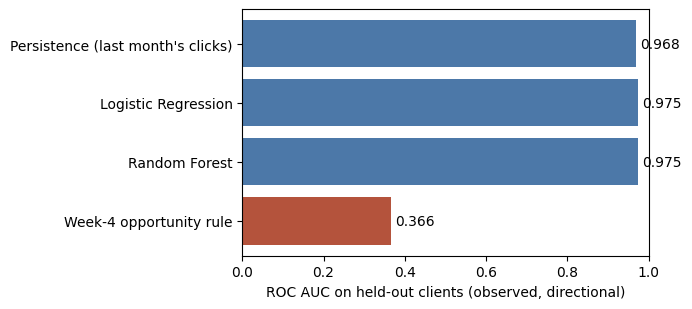

In [7]:
os.makedirs("work/figures", exist_ok=True)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(results.method[::-1], results.roc_auc[::-1], color=["#b4533c", "#4c78a8", "#4c78a8", "#4c78a8"])
ax.set_xlim(0, 1); ax.set_xlabel("ROC AUC on held-out clients (observed, directional)")
for y, v in enumerate(results.roc_auc[::-1]): ax.text(v + 0.01, y, f"{v:.3f}", va="center")
plt.tight_layout(); plt.savefig("work/figures/capstone_model_vs_baseline.png", dpi=150); plt.show()


## 8. Five-minute demo outline

Structure: question, method, one chart, one honest result, one recommendation.

| Time | Segment | What I say |
|---|---|---|
| 0:00-0:30 | **Question** | Editors have thousands of pages and limited time. Which pages should they review first? |
| 0:30-1:15 | **Why it matters** | FlyRank's public paper tells editors to improve click capture on pages that already rank, but gives portfolio averages. I built the page-level version. |
| 1:15-2:15 | **Method** | Features from the previous 30 days, label from the next 30. Whole clients held out, so the test is on sites the model never saw. Compared a rule I built first, a "rank by last month's clicks" check, Logistic Regression and a Random Forest. |
| 2:15-3:15 | **One chart** | Show the ROC AUC bars from section 7: 0.975, 0.975, 0.968 against 0.366 for my rule. |
| 3:15-4:15 | **One honest result** | The models barely beat last month's clicks. Complexity did not earn its place, and my own rule answered a different question. I report that instead of hiding it. |
| 4:15-5:00 | **One recommendation** | Review the top-ranked under-clicked pages first: the first 10 hold about 19% of the estimated ceiling. A person checks every row; nothing is automated. Live paper: https://aleeza-nadeem.github.io/flyrank-ml-internship-starter/ |

**If asked:** why group by client (random rows leak a client's habits); why not claim a refresh causes clicks (association only); what I would do next (test on a newer data release and track reviewed pages against untouched ones).

## 9. Shareable cuts

**Social post (methodology):**

I tried to answer a simple question: which pages should a content team review first? The part I want to share is the method, not the score. I held out whole clients instead of random rows, and I added a dumb check that just ranks pages by last month's clicks. Result: my models scored a ROC AUC of 0.975, but the dumb check scored 0.968, so the models added very little. My own first rule scored 0.366 because it answered a different question. Lesson: build the baseline first, split by client, and report it when the fancy model does not help. Built during my FlyRank ML internship on an anonymized dataset. Read the paper: https://aleeza-nadeem.github.io/flyrank-ml-internship-starter/

**Employer-facing summary (3 sentences):**

I built a human-reviewed content action queue that ranks pages by how many clicks they are likely to earn next, with reason codes, review rules and monitoring triggers. I trained and tested it on 26,612 anonymized pages from 31 clients in the FlyRank ML Internship dataset, holding out whole clients to keep the test honest. It showed that machine-learning models (ROC AUC 0.975) beat my rule-based baseline (0.366) but added little over simply ranking by last month's clicks (0.968), so I shipped the queue as decision support and published the paper with its limits.

## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [x] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [x] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
